ref：
* https://greglandrum.github.io/rdkit-blog/posts/2025-02-08-more-on-generalized-substructure-search.html
* https://greglandrum.github.io/rdkit-blog/posts/2021-08-03-generalized-substructure-search.html
* https://greglandrum.github.io/rdkit-blog/posts/2022-04-05-searching-with-generic-groups.html
* https://github.com/LingjieBao1998/cs1610_work/blob/main/query_substructure/query_sub.ipynb

In [1]:
from rdkit import Chem
from rdkit.Chem import rdMolEnumerator
from rdkit.Chem import rdTautomerQuery
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.drawOptions.minFontSize = 10
Draw.SetComicMode(IPythonConsole.drawOptions)
from rdkit.Chem import rdDepictor
rdDepictor.SetPreferCoordGen(True)
import rdkit
print(rdkit.__version__)
import time
print(time.asctime())
import pandas as pd

2024.03.5
Wed Aug 13 20:02:37 2025


In [2]:
from rdkit.Chem import PandasTools

# 1. 读取 sdf 文件，直接得到 pandas DataFrame
sdf_file = "../data/mol_nmrshift_nmrshiftdb2_2024_all_processed.sdf"  # 替换为你的 sdf 文件路径
df = PandasTools.LoadSDF(sdf_file)

# 2. 查看 DataFrame
df.head()

[17:19:12] The 2 defining bonds for an atropisomer are co-planar - atoms are: 8 9
[17:19:17] The 2 defining bonds for an atropisomer are co-planar - atoms are: 8 9
[17:19:17] The 2 defining bonds for an atropisomer are co-planar - atoms are: 8 9


,shift,smiles,ID,ROMol
0,"{""0"": 18.3, ""1"": 41.8, ""2"": 33.5, ""3"": 42.2, ""...",CC1(C)CCC[C@@]2(C)C1CC=C(C=O)[C@]2(O)C=O,,<rdkit.Chem.rdchem.Mol object at 0x7949eb585310>
1,"{""0"": 37.6, ""1"": 29.9, ""2"": 64.9, ""3"": 35.8, ""...",C[C@H]1CC[C@@]23[C@@H]1CC[C@]2(C)C=C(CO)[C@@H]3C,,<rdkit.Chem.rdchem.Mol object at 0x7949e0840660>
2,"{""1"": 132.1, ""2"": 60.5, ""4"": 90.0, ""5"": 23.5, ...",CN1C(C)(C)C=[N+]([O-])C1(C)C,,<rdkit.Chem.rdchem.Mol object at 0x7949e08406d0>
3,"{""0"": 110.7, ""1"": 113.0, ""2"": 147.2, ""3"": 150....",C=C[C@@]1(C)C[C@@H](O)[C@](OC(C)=O)(C(C)C)C[C@...,,<rdkit.Chem.rdchem.Mol object at 0x7949e08407b0>
4,"{""0"": 177.0, ""3"": 31.0, ""5"": 15.3, ""6"": 19.8, ...",CC(C)C(O)C(=O)N(C)C1CCC2=CC3=CC[C@]4(C)[C@@H](...,,<rdkit.Chem.rdchem.Mol object at 0x7949e0840820>


,shift,smiles,ID,ROMol
0,"{""0"": 18.3, ""1"": 41.8, ""2"": 33.5, ""3"": 42.2, ""...",CC1(C)CCC[C@@]2(C)C1CC=C(C=O)[C@]2(O)C=O,,
1,"{""0"": 37.6, ""1"": 29.9, ""2"": 64.9, ""3"": 35.8, ""...",C[C@H]1CC[C@@]23[C@@H]1CC[C@]2(C)C=C(CO)[C@@H]3C,,
2,"{""1"": 132.1, ""2"": 60.5, ""4"": 90.0, ""5"": 23.5, ...",CN1C(C)(C)C=[N+]([O-])C1(C)C,,
3,"{""0"": 110.7, ""1"": 113.0, ""2"": 147.2, ""3"": 150....",C=C[C@@]1(C)C[C@@H](O)[C@](OC(C)=O)(C(C)C)C[C@...,,
4,"{""0"": 177.0, ""3"": 31.0, ""5"": 15.3, ""6"": 19.8, ...",CC(C)C(O)C(=O)N(C)C1CCC2=CC3=CC[C@]4(C)[C@@H](...,,
...,...,...,...,...
32793,"{""0"": 109.5, ""1"": 146.5, ""2"": 145.1, ""3"": 113....",CCO[C@@H](c1ccc(O)c(OC)c1)C(CO)c1cc(OC)c(O)c(O...,,
32794,"{""0"": 95.215, ""1"": 157.57, ""2"": 95.865, ""3"": 1...",Oc1cc(O)c2c(c1)O[C@@H](c1cc(O)c(O)c(O)c1)[C@@H...,,
32795,"{""0"": 177.03, ""1"": 34.099999999999994, ""2"": 25...",CCCCCCCCCCCCCC(=O)O,,
32796,"{""2"": 54.0, ""3"": 21.3, ""4"": 139.9, ""5"": 118.1}",C=CC1(C)NN1,,

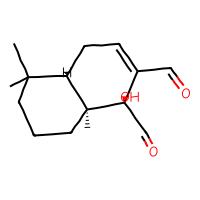
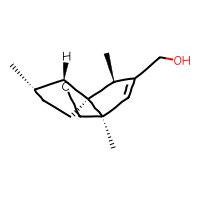
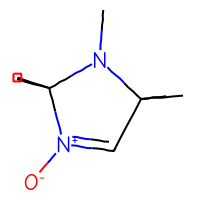
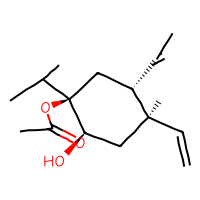
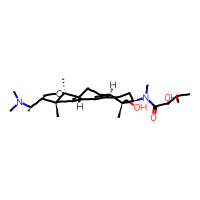
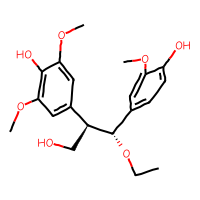
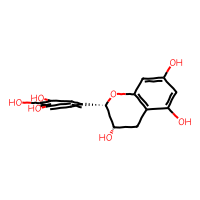
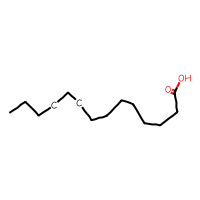
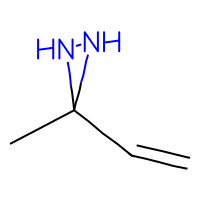
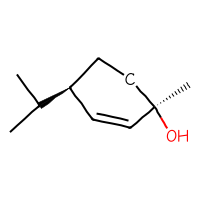

In [3]:
df

In [4]:
def strard_mol_fn(smiles):
    try:
        new_smiles = Chem.MolToSmiles(Chem.MolFromSmiles(Chem.MolToSmiles(Chem.MolFromSmiles(smiles))))
        return new_smiles
    except Exception as e:
        print(e)
        return ""

In [5]:
df["cano_smiles"] = df["smiles"].apply(strard_mol_fn)

,shift,smiles,ID,ROMol,cano_smiles
0,"{""0"": 18.3, ""1"": 41.8, ""2"": 33.5, ""3"": 42.2, ""...",CC1(C)CCC[C@@]2(C)C1CC=C(C=O)[C@]2(O)C=O,,,CC1(C)CCC[C@@]2(C)C1CC=C(C=O)[C@]2(O)C=O
1,"{""0"": 37.6, ""1"": 29.9, ""2"": 64.9, ""3"": 35.8, ""...",C[C@H]1CC[C@@]23[C@@H]1CC[C@]2(C)C=C(CO)[C@@H]3C,,,C[C@H]1CC[C@@]23[C@@H]1CC[C@]2(C)C=C(CO)[C@@H]3C
2,"{""1"": 132.1, ""2"": 60.5, ""4"": 90.0, ""5"": 23.5, ...",CN1C(C)(C)C=[N+]([O-])C1(C)C,,,CN1C(C)(C)C=[N+]([O-])C1(C)C
3,"{""0"": 110.7, ""1"": 113.0, ""2"": 147.2, ""3"": 150....",C=C[C@@]1(C)C[C@@H](O)[C@](OC(C)=O)(C(C)C)C[C@...,,,C=C[C@@]1(C)C[C@@H](O)[C@](OC(C)=O)(C(C)C)C[C@...
4,"{""0"": 177.0, ""3"": 31.0, ""5"": 15.3, ""6"": 19.8, ...",CC(C)C(O)C(=O)N(C)C1CCC2=CC3=CC[C@]4(C)[C@@H](...,,,CC(C)C(O)C(=O)N(C)C1CCC2=CC3=CC[C@]4(C)[C@@H](...
...,...,...,...,...,...
32793,"{""0"": 109.5, ""1"": 146.5, ""2"": 145.1, ""3"": 113....",CCO[C@@H](c1ccc(O)c(OC)c1)C(CO)c1cc(OC)c(O)c(O...,,,CCO[C@@H](c1ccc(O)c(OC)c1)C(CO)c1cc(OC)c(O)c(O...
32794,"{""0"": 95.215, ""1"": 157.57, ""2"": 95.865, ""3"": 1...",Oc1cc(O)c2c(c1)O[C@@H](c1cc(O)c(O)c(O)c1)[C@@H...,,,Oc1cc(O)c2c(c1)O[C@@H](c1cc(O)c(O)c(O)c1)[C@@H...
32795,"{""0"": 177.03, ""1"": 34.099999999999994, ""2"": 25...",CCCCCCCCCCCCCC(=O)O,,,CCCCCCCCCCCCCC(=O)O
32796,"{""2"": 54.0, ""3"": 21.3, ""4"": 139.9, ""5"": 118.1}",C=CC1(C)NN1,,,C=CC1(C)NN1

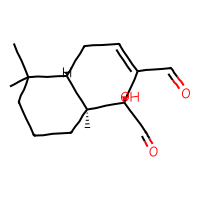
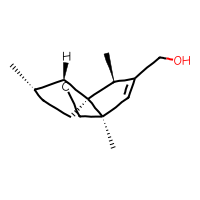
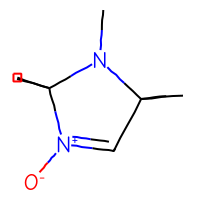
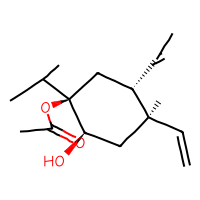
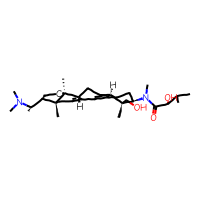
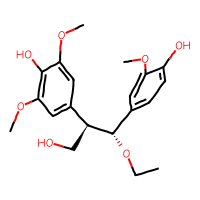
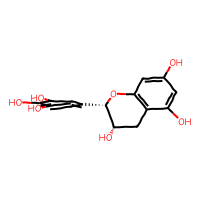
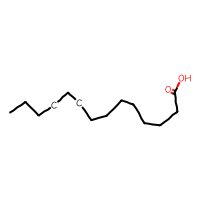
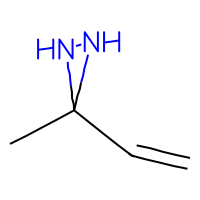
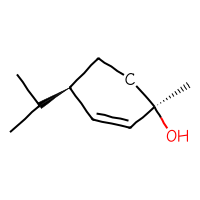

In [6]:
df

In [7]:
from tqdm import tqdm
t1=time.time()
data = []
for idx in tqdm(df.index):
    smi = df.loc[idx, "cano_smiles"]
    mol = Chem.MolFromSmiles(smi)
    if not ((idx+1)%50000):
        print(f"Processed {idx+1} molecules in {(time.time()-t1):.1f} seconds")
    if mol is None: #or mol.GetNumAtoms()>50
        continue
    fp = Chem.PatternFingerprint(mol,fpSize=1024,tautomerFingerprints=True)
    data.append((smi,fp))
t2=time.time()

100%|██████████| 32798/32798 [00:05<00:00, 6039.99it/s]


In [8]:
from rdkit.Chem import rdSubstructLibrary
t1=time.time()
mols = rdSubstructLibrary.CachedTrustedSmilesMolHolder()
fps = rdSubstructLibrary.TautomerPatternHolder(1024)
for smi,fp in data:
    mols.AddSmiles(smi)
    fps.AddFingerprint(fp)
library = rdSubstructLibrary.SubstructLibrary(mols,fps)
t2=time.time()
print(f"That took {t2-t1:.2f} seconds. The library has {len(library)} molecules.")

That took 0.02 seconds. The library has 32798 molecules.


In [9]:
# library_save_path = "data/chemb_ssslib.pkl"
import pickle
library_save_path = "../data/mol_nmrshift_nmrshiftdb2_2024_all_processed.sdf_ssslib.pkl"
pickle.dump(library,open(library_save_path,'wb+'))

OC(=O)C1=C[NH]C2=CC=CC=C2C1=O
O=C(O)c1c[nH]c2ccccc2c1=O


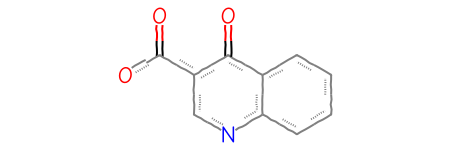

In [10]:
qry = Chem.MolFromSmarts('OC(C1=C[NH]C2=CC=CC=C2C1=O)=O')
print(Chem.MolToSmiles(qry))
print(Chem.MolToSmiles(Chem.MolFromSmiles(Chem.MolToSmiles(qry))))
qry = Chem.MolFromSmarts(Chem.MolToSmiles(Chem.MolFromSmiles(Chem.MolToSmiles(qry))))
qry

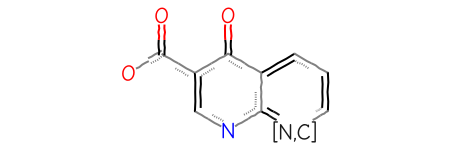

In [11]:
qry = Chem.MolFromSmarts('OC(C1=CNC2=[N,C]C=CC=C2C1=O)=O')
qry = Chem.MolFromSmarts(Chem.MolToSmarts(Chem.MolFromSmarts(Chem.MolToSmarts(qry))))
qry

In [12]:
# qry = Chem.MolFromSmarts('O=S(=O)')
# qry

In [13]:
# qry = Chem.MolFromSmarts('c1ccccc1')
# qry

In [14]:
# qry = Chem.MolFromSmarts('O=C([OH])c1c[nH]c2ccccc2c1=O')
# qry

In [15]:
# qry = Chem.MolFromSmarts('O=C([OH])c1c[nH]c2ncccc2c1=O')
# qry

In [16]:
with open(library_save_path,'rb') as file:
    slib = pickle.load(file)
print(f'SubstructLibrary loaded with {len(slib)} molecules')
mids = slib.GetMatches(qry)
print(f'{len(mids)} results')

SubstructLibrary loaded with 32798 molecules
0 results


In [17]:
mids = slib.GetMatches(qry, numThreads=10)
print(f'{len(mids)} results')

ms = [slib.GetMolHolder().GetMol(x) for x in mids]
[mol.GetSubstructMatch(qry) for mol in ms]
legends = [slib.GetKeyHolder().GetKey(x) for x in mids[:0]]
Draw.MolsToGridImage(ms,legends=legends,subImgSize=(250,200))

0 results


[17:19:32] 

****
Pre-condition Violation
no draw context
Violation occurred on line 211 in file /project/build/temp.linux-x86_64-cpython-310/rdkit/Code/GraphMol/MolDraw2D/MolDraw2DCairo.cpp
Failed Expression: dp_cr
----------
Stacktrace:
----------
****



RuntimeError: Pre-condition Violation
	no draw context
	Violation occurred on line 211 in file Code/GraphMol/MolDraw2D/MolDraw2DCairo.cpp
	Failed Expression: dp_cr
	RDKIT: 2025.03.2
	BOOST: 1_85


OC(=O)C1=C[NH]C2=CC=CC=C2C1=O
O=C(O)c1c[nH]c2ccccc2c1=O


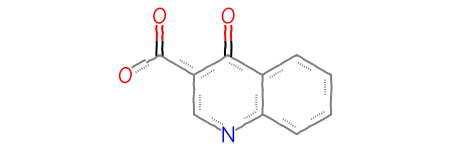

In [18]:
qry = Chem.MolFromSmarts('OC(C1=C[NH]C2=CC=CC=C2C1=O)=O')
print(Chem.MolToSmiles(qry))
print(Chem.MolToSmiles(Chem.MolFromSmiles(Chem.MolToSmiles(qry))))
qry = Chem.MolFromSmarts(Chem.MolToSmiles(Chem.MolFromSmiles(Chem.MolToSmiles(qry))))
qry

1 results


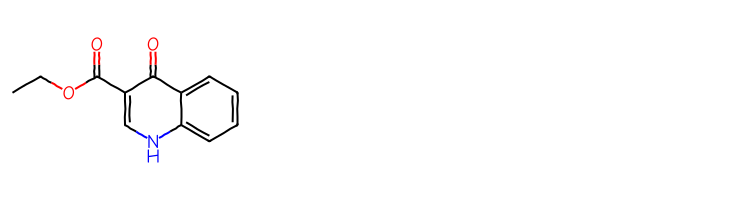

In [21]:
mids = slib.GetMatches(qry, numThreads=10)
print(f'{len(mids)} results')

ms = [slib.GetMolHolder().GetMol(x) for x in mids]
[mol.GetSubstructMatch(qry) for mol in ms]
legends = [slib.GetKeyHolder().GetKey(x) for x in mids[:0]]
Draw.MolsToGridImage(ms,legends=legends,subImgSize=(250,200))

In [ ]:
for m in ms:
    print(Chem.MolToSmiles(m))


CCOC(=O)c1c[nH]c2ccccc2c1=O
CCOC(=O)c1c[nH]c2c(C)c(F)c(F)cc2c1=O
CCOC(=O)c1c[nH]c2c(COC(C)=O)c(F)c(F)cc2c1=O
CCOC(=O)c1c[nH]c2c(SC)c(F)c(F)cc2c1=O
O=C(O)c1c[nH]c2c(ccc3nccnc32)c1=O


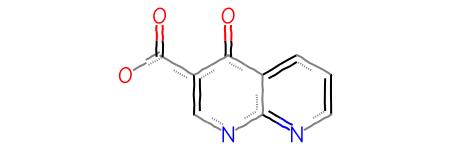

In [ ]:
qry = Chem.MolFromSmarts('OC(C1=CNC2=NC=CC=C2C1=O)=O')
qry = Chem.MolFromSmarts(Chem.MolToSmarts(Chem.MolFromSmarts(Chem.MolToSmarts(qry))))
qry

In [ ]:
mids = slib.GetMatches(qry, numThreads=10)
print(f'{len(mids)} results')

ms = [slib.GetMolHolder().GetMol(x) for x in mids]
[mol.GetSubstructMatch(qry) for mol in ms]
legends = [slib.GetKeyHolder().GetKey(x) for x in mids[:0]]
Draw.MolsToGridImage(ms,legends=legends,subImgSize=(250,200))

0 results


[11:08:54] 

****
Pre-condition Violation
no draw context
Violation occurred on line 211 in file /project/build/temp.linux-x86_64-cpython-310/rdkit/Code/GraphMol/MolDraw2D/MolDraw2DCairo.cpp
Failed Expression: dp_cr
----------
Stacktrace:
----------
****



RuntimeError: Pre-condition Violation
	no draw context
	Violation occurred on line 211 in file Code/GraphMol/MolDraw2D/MolDraw2DCairo.cpp
	Failed Expression: dp_cr
	RDKIT: 2025.03.2
	BOOST: 1_85


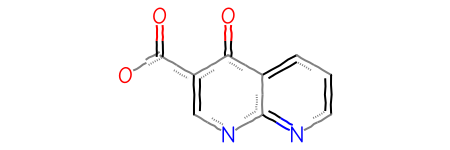

In [ ]:
qry = Chem.MolFromSmarts('OC(C1=CNC2=NC=CC=C2C1=O)=O')
qry = Chem.MolFromSmarts(Chem.MolToSmarts(Chem.MolFromSmarts(Chem.MolToSmarts(qry))))
qry